# PASSO 1) Treinamento e Carregamento do modelo do experimento do joão

In [1]:
import pandas as pd
import os
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

In [2]:
# Baixar os recursos necessários do NLTK
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
PATH_BASE_NOMES = os.getenv('PATH_BASE_NOMES')
PATH_BASE_PALAVRAS_COMUNS = os.getenv('PATH_BASE_PALAVRAS_COMUNS')
PATH_GABARITO_MODELO_1 = os.getenv('PATH_GABARITO_MODELO_1')

In [5]:
# Carregar os dados originais
df_nomes = pd.read_csv(PATH_BASE_NOMES)
df_nomes.shape

(102561, 1)

In [6]:
df_palavras = pd.read_csv(PATH_BASE_PALAVRAS_COMUNS)
df_palavras.shape

(245019, 1)

In [7]:
# Carregar os dados originais
df_nomes = pd.read_csv(PATH_BASE_NOMES).drop_duplicates()
df_nomes['y'] = 1
    
df_palavras = pd.read_csv(PATH_BASE_PALAVRAS_COMUNS).drop_duplicates()
df_palavras['y'] = 0

## 1.1) Remoção dos tokens que possuem ocorrência tanto na base de NOMES quanto na base de PALAVRAS

### 1.1.1) Realizo a verificação dos nomes, que estão na base de nomes e também estão presentes na base da palavras, e os apresento na tabela abaixo:

In [6]:
duplicates = df_palavras[df_palavras['X'].isin(df_nomes['X'].to_list())]
duplicates

,X,y
0,AARAO,0
12,ABADE,0
16,ABADIA,0
17,ABADIAS,0
647,ABAS,0
...,...,...
244672,ZELE,0
244673,ZELEI,0
244686,ZENITE,0
244734,ZERES,0


### 1.1.2) Após a verificação realizo a remoção dos dados contidos em ambas as bases

In [7]:
df_palavras = df_palavras[~df_palavras['X'].isin(df_nomes['X'].to_list())].reset_index(drop=True)
df = pd.concat([df_nomes, df_palavras])
df.shape

(345694, 2)

In [8]:
# nomes
df[df['y'] == 1].shape

(102561, 2)

In [9]:
# nomes
df[df['y'] == 0].shape

(243133, 2)

In [10]:
df_palavras = df_palavras[~df_palavras['X'].isin(df_nomes['X'].to_list())].reset_index(drop=True).sample(n=len(df_nomes), random_state=42)
df = pd.concat([df_nomes, df_palavras])
df.shape

(205122, 2)

In [11]:
# nomes
df[df['y'] == 1].shape

(102561, 2)

In [12]:
# nomes
df[df['y'] == 0].shape

(102561, 2)

### 1.1.3) verificando se ainda exitem repetição de determinados tokens em ambas as bases

In [13]:
duplicates = df_palavras[df_palavras['X'].isin(df_nomes['X'].to_list())]
duplicates

,X,y


## 1.2) Após o tratamento, o código se mantém como feito no experimento orignial

### o restante do código se mantém de acordo com o que está no github

In [ ]:
# Carregar o arquivo gabarito_formatado.csv
unique_words_df = pd.read_csv(PATH_GABARITO_MODELO_1)

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

# Converter todos os valores '-1' para '0' na coluna 'y'
unique_words_df['y'] = unique_words_df['y'].replace(-1, 0)

words_with_negative_label = unique_words_df[unique_words_df['y'] == -1]

words_with_negative_label_list = words_with_negative_label['palavra'].tolist()

print(words_with_negative_label_list)

[]


In [15]:
# Usar o alfabeto e bigrams
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]

vectorizer = CountVectorizer(analyzer='char', vocabulary=alfabeto_bigrams, lowercase=False, ngram_range=(2, 2))

In [16]:
# Vetorizar os dados de treino completos
X_train_vector = vectorizer.fit_transform(df['X'])
y_train = df['y']

# Vetorizar as palavras únicas para teste
X_unique_words_vector = vectorizer.transform(unique_words_df['palavra'])
y_true = unique_words_df['y']


SVC - Accuracy: 0.7780557541100787, Precision: 0.355194428322693, Recall: 0.8236877523553163, F1 Score: 0.49635036496350365
              precision    recall  f1-score   support

           0       0.97      0.77      0.86      4853
           1       0.36      0.82      0.50       743

    accuracy                           0.78      5596
   macro avg       0.66      0.80      0.68      5596
weighted avg       0.89      0.78      0.81      5596



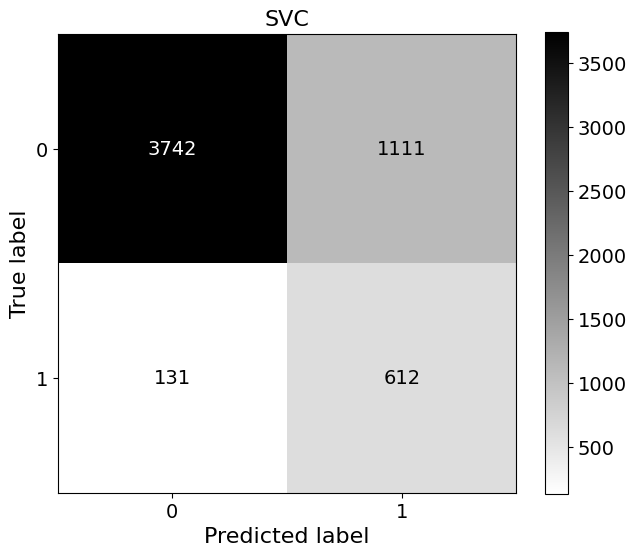

RandomForest - Accuracy: 0.8422087205146533, Precision: 0.4529569892473118, Recall: 0.9071332436069987, F1 Score: 0.6042133572389063
              precision    recall  f1-score   support

           0       0.98      0.83      0.90      4853
           1       0.45      0.91      0.60       743

    accuracy                           0.84      5596
   macro avg       0.72      0.87      0.75      5596
weighted avg       0.91      0.84      0.86      5596



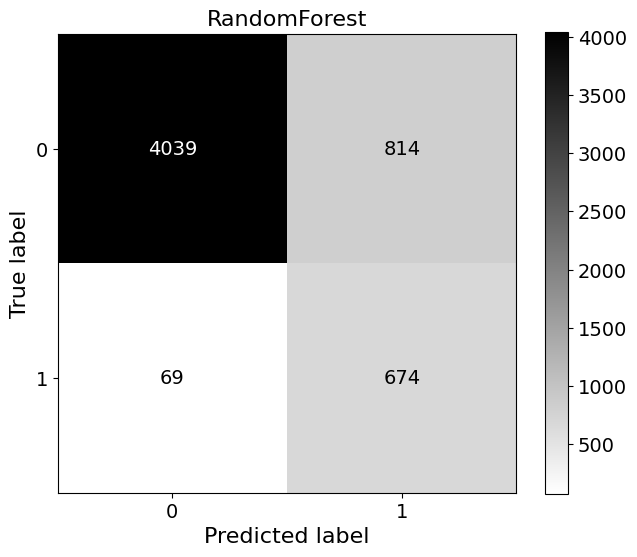

GradientBoosting - Accuracy: 0.5939957112223017, Precision: 0.21716611172770994, Recall: 0.7900403768506057, F1 Score: 0.3406848520023215
              precision    recall  f1-score   support

           0       0.95      0.56      0.71      4853
           1       0.22      0.79      0.34       743

    accuracy                           0.59      5596
   macro avg       0.58      0.68      0.52      5596
weighted avg       0.85      0.59      0.66      5596



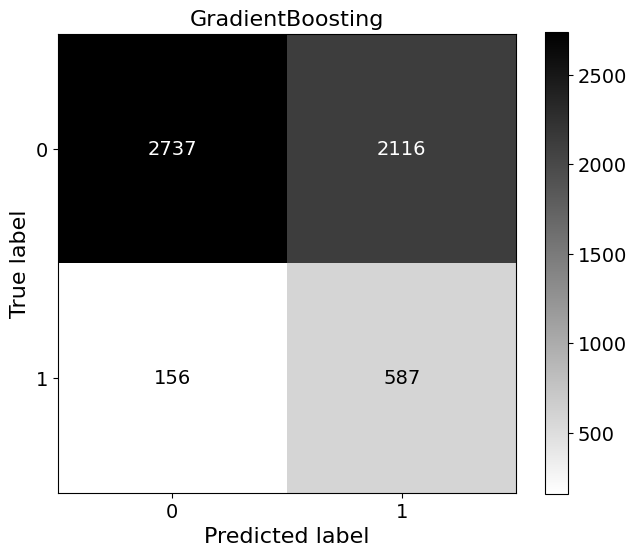

LogisticRegression - Accuracy: 0.6801286633309507, Precision: 0.2612859097127223, Recall: 0.7711978465679677, F1 Score: 0.39032697547683926
              precision    recall  f1-score   support

           0       0.95      0.67      0.78      4853
           1       0.26      0.77      0.39       743

    accuracy                           0.68      5596
   macro avg       0.61      0.72      0.59      5596
weighted avg       0.86      0.68      0.73      5596



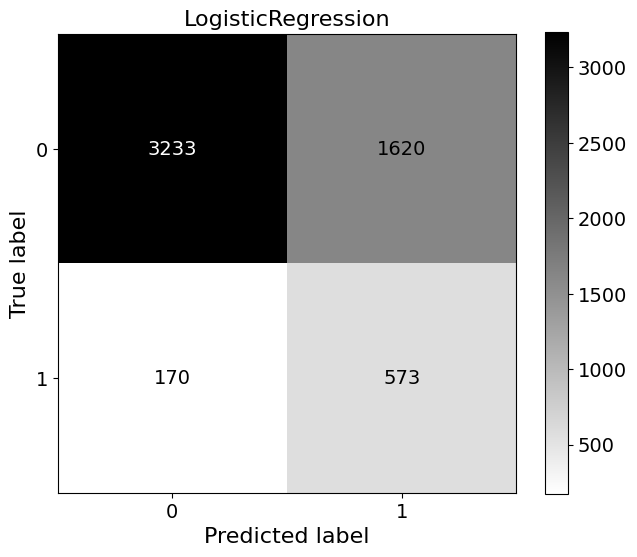

                Model  Accuracy  Precision    Recall  F1 Score  \
0                 SVC  0.778056   0.355194  0.823688  0.496350   
1        RandomForest  0.842209   0.452957  0.907133  0.604213   
2    GradientBoosting  0.593996   0.217166  0.790040  0.340685   
3  LogisticRegression  0.680129   0.261286  0.771198  0.390327   

   False Negatives  
0              131  
1               69  
2              156  
3              170  

Falsos Negativos para SVC:
['DUTRA', 'NASCIMENTO', 'COELHO', 'VOGADO', 'GUERREIRO', 'BARROSO', 'PENTEADO', 'BRAS', 'CARDOSO', 'TORRES', 'ZHAMMYRARAUJO', 'FERREIRA', 'CORDEIRO', 'LOPES', 'CAMPOS', 'CUNHA', 'BARRA', 'ESPIRITO', 'NOBRE', 'TOURINHO', 'FERRAZ', 'BENTES', 'SOARES', 'AZEVEDO', 'BEZERROS', 'PANTOJA', 'TAVARES', 'DAMASCENO', 'BARROS', 'FREIRE', 'VAVA', 'PASSOS', 'CARMO', 'HOBBIES', 'CAVALCANTE', 'PIMENTEL', 'CAMARGO', 'COSTA', 'FRAGOSO', 'NATIVIDADE', 'FREITAS', 'ROBISPIERRE', 'HADAD', 'KYRIACOPOULOS', 'COUTINHO', 'CASTRO', 'ARRUDA', 'MORAIS', 'VIEI

In [ ]:
# Treinar os modelos
classifiers = {
    'SVC': SVC(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42)
}

# Dicionário para armazenar as métricas
metrics = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'False Negatives': []
}

# Dicionário para armazenar os falsos negativos
false_negatives = {}

for model_name, classifier in classifiers.items():
    classifier.fit(X_train_vector, y_train)
    y_pred = classifier.predict(X_unique_words_vector)

    # Calcular as métricas
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_true, y_pred)
    fn = cm[1, 0]  # Falsos Negativos

    # Adicionar as métricas ao dicionário
    metrics['Model'].append(model_name)
    metrics['Accuracy'].append(accuracy)
    metrics['Precision'].append(precision)
    metrics['Recall'].append(recall)
    metrics['F1 Score'].append(f1)
    metrics['False Negatives'].append(fn)

    # Encontrar os falsos negativos
    fn_indices = [i for i, (true, pred) in enumerate(zip(y_true, y_pred)) if true == 1 and pred == 0]
    false_negatives[model_name] = unique_words_df.iloc[fn_indices]['palavra'].tolist()

    # Imprimir o relatório de classificação
    report = classification_report(y_true, y_pred)
    print(f"{model_name} - Accuracy: {accuracy}, Precision: {precision}, Recall: {recall}, F1 Score: {f1}")
    print(report)

    # Gerar a matriz de confusão
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    
    fig, ax = plt.subplots(figsize=(7.4, 6))
    disp.plot(cmap='binary', text_kw={"fontsize": 14}, ax=ax)
    plt.title(model_name, fontsize=16)
    plt.xlabel("Predicted label", fontsize=16)
    plt.ylabel("True label", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    cbar = ax.images[-1].colorbar
    cbar.ax.tick_params(labelsize=14)
    plt.show()

# Criar o dataframe com as métricas
metrics_df = pd.DataFrame(metrics)
print(metrics_df)

# Exibir os falsos negativos para cada modelo
for model_name, fn_list in false_negatives.items():
    print(f"\nFalsos Negativos para {model_name}:")
    print(fn_list)

## 1.2) Salvando modelo para utilização na segunda parte do experimento do corretor

In [ ]:
from sklearn.pipeline import Pipeline
from joblib import dump

In [13]:
pipeline = Pipeline([
    ('vectorizer', vectorizer),
    ('classifier', classifiers['RandomForest'])
])

In [14]:
dump(pipeline, 'rf_exp2.joblib', compress=True)

['rf_exp2.joblib']